# Скользящая проверка и расширенные признаки

**Итог.** Качество модели заметно зависит от месяца (logloss от 0,107 до 0,252). Расширенные признаки дают небольшой средний выигрыш, длинная история обучения лучше короткой, поправка вероятностей к доле оттока качество не улучшает.

В `07_churn_model.ipynb` модель обучалась на феврале 2017 и проверялась на марте: одно сравнение двух месяцев. Здесь проверка повторяется на ряде месяцев и учитывает два
уточнения.

**Зазор между обучением и тестом.** Метка клиента, у которого подписка заканчивается в месяце M, окончательно известна лишь через 30 дней после окончания подписки, то есть
примерно к началу месяца M+2. Поэтому при прогнозе месяца T (на его первый день) обучение может использовать только месяцы до T−2. В схеме «обучение на феврале, тест на марте»
метки февраля на 1 марта известны не полностью; в этом ноутбуке зазор соблюдается.

**Данные.** Метки: собственная разметка по транзакциям (`scripts/07_labels_months.py`) для месяцев с января 2016 по январь 2017 и официальные метки для февраля и марта 2017.
Признаки: `scripts/08_features_v2.py` (прежние 32 признака и 20 новых, всего 52), все считаются на первый день месяца окончания подписки по данным до этой даты.

**Что сравнивается.** Тестовые месяцы: июль 2016 .. март 2017 (девять месяцев). Четыре конфигурации:
- A: прежние 32 признака, обучение на всех допустимых месяцах;
- B: 52 признака, все допустимые месяцы;
- C: 52 признака, три последних допустимых месяца (T−4 .. T−2);
- D: 52 признака, один последний допустимый месяц (T−2).

Модель везде LightGBM с одними параметрами (из `07_churn_model.ipynb`), число деревьев подобрано один раз на пилотном месяце. Чтобы ноутбук помещался в память, обучающие месяцы берутся
с долей клиентов `TRAIN_SHARE` процентов (по хешу `msno`); тестовые месяцы используются целиком.

In [1]:
import time

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from scipy.optimize import brentq
from scipy.special import expit, logit
from sklearn.metrics import average_precision_score, log_loss, roc_auc_score
from sklearn.model_selection import train_test_split

P = "/workspace/data/processed/"
LABELS = P + "labels_months.parquet"
ALL_MONTHS = [f"2016-{m:02d}-01" for m in range(1, 13)] + ["2017-01-01", "2017-02-01", "2017-03-01"]
TEST_MONTHS = ALL_MONTHS[6:]  # июль 2016 .. март 2017
TRAIN_SHARE = 20  # процент клиентов обучающих месяцев
RARE_MIN = 200  # порог редкой категории в обучающей выборке
SEED = 42
INK, BLUE, ORANGE, GREEN, GRAY, PINK = "#2b2f36", "#0072B2", "#E69F00", "#009E73", "#8a8f98", "#CC79A7"

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9cdd4",
    "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK, "text.color": INK,
    "axes.grid": True, "grid.color": "#e8eaee", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10,
})

NUM_V1 = [
    "last_plan_days", "last_list_price", "last_paid", "last_auto_renew", "last_is_cancel", "last_discount",
    "days_to_expire", "days_since_last_tx", "tenure_days", "n_tx", "n_cancel", "share_cancel", "n_paid_tx",
    "total_paid", "avg_paid", "share_zero_paid", "share_discount", "share_auto_renew", "n_plans", "n_methods",
    "n_tx_30d", "n_tx_90d", "n_plan_changes", "n_method_changes", "n_lapses", "has_profile", "age", "reg_tenure_days",
]
CAT_V1 = ["last_method", "city", "gender", "registered_via"]
NUM_NEW = [
    "prev_plan_days", "prev_paid", "prev_auto_renew", "prev_is_cancel", "plan_changed", "method_changed",
    "auto_renew_changed", "days_between_last_two_tx", "ex_minus_td", "ex_minus_td_minus_plan", "paid_per_day",
    "list_per_day", "discount_ratio", "n_cancel_5", "avg_paid_5", "avg_plan_days_5", "share_auto_5", "n_expired", "lapse_share",
]
CAT_NEW = ["prev_method"]
NUM_ALL, CAT_ALL = NUM_V1 + NUM_NEW, CAT_V1 + CAT_NEW
F1 = NUM_V1 + CAT_V1
F2 = NUM_ALL + CAT_ALL
print("признаков: F1 =", len(F1), " F2 =", len(F2))

con = duckdb.connect()
con.execute("SET memory_limit='4GB'; SET threads=2; SET enable_progress_bar=false")

признаков: F1 = 32  F2 = 52


## 1. Доля оттока по месяцам
Доля оттока по собственной и официальной разметке для каждого месяца. Для февраля 2017 есть обе разметки: их различие показывает, насколько собственная разметка (используется для месяцев до января 2017)
отличается от официальной. Тестовыми метками февраля и марта 2017 служат официальные.

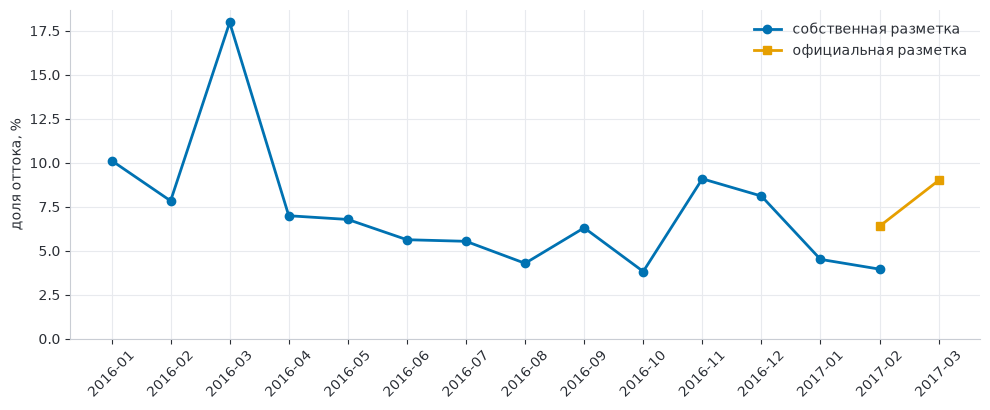

source,official,own,official_клиентов,own_клиентов
month,,,,
2016-01,NaN,10.13,NaN,756442.0
2016-02,NaN,7.83,NaN,694129.0
2016-03,NaN,17.97,NaN,806704.0
2016-04,NaN,6.99,NaN,730156.0
2016-05,NaN,6.78,NaN,738315.0
2016-06,NaN,5.63,NaN,742202.0
2016-07,NaN,5.54,NaN,766155.0
2016-08,NaN,4.29,NaN,798862.0
2016-09,NaN,6.30,NaN,844477.0


In [2]:
rates = con.sql(f'''
    SELECT
        expire_month,
        source,
        count(*) AS clients,
        avg(is_churn) AS churn_rate
    FROM '{LABELS}'
    GROUP BY expire_month, source
    ORDER BY expire_month, source
''').df()
rates["month"] = rates.expire_month.dt.strftime("%Y-%m")

fig, ax = plt.subplots(figsize=(10, 4.2))
for src, color, marker in [("own", BLUE, "o"), ("official", ORANGE, "s")]:
    g = rates[rates.source == src]
    ax.plot(g.month, 100 * g.churn_rate, color=color, marker=marker, lw=2, label={"own": "собственная разметка", "official": "официальная разметка"}[src])
ax.set_ylabel("доля оттока, %")
ax.set_ylim(0, None)
ax.tick_params(axis="x", labelrotation=45)
ax.legend(frameon=False)
plt.tight_layout()
fig_rates = fig
plt.show()
rates.pivot(index="month", columns="source", values="churn_rate").mul(100).round(2).join(
    rates.pivot(index="month", columns="source", values="clients").add_suffix("_клиентов"))

## 2. Загрузка данных
Функции `load_month` и подготовки признаков. Подготовка (обрезка выбросов по квантилям 0,1% и 99,9%, объединение редких категорий в «other», пропуск в «missing») обучается только на обучающем окне
каждой конфигурации и применяется к тесту. Обучающие месяцы (январь 2016 .. январь 2017) загружаются один раз с долей клиентов `TRAIN_SHARE`.

In [3]:
def load_month(month: str, source: str, share: int | None = None) -> pd.DataFrame:
    '''Загружает признаки и метки одного месяца.

    Args:
        month (str): первый день месяца окончания подписки ('YYYY-MM-01').
        source (str): источник меток ('own' или 'official').
        share (int | None): процент клиентов по хешу `msno`; None: все клиенты.

    Returns:
        pd.DataFrame: признаки (`features_v2`) и метка `is_churn`.
    '''
    cond = f"AND hash(f.msno) % 100 < {share}" if share else ""
    return con.sql(f'''
        SELECT
            f.*,
            l.is_churn
        FROM '{P}features_v2_{month[:7]}.parquet' f
        JOIN '{LABELS}' l ON l.msno = f.msno AND l.expire_month = f.expire_month
        WHERE l.source = '{source}'
            {cond}
    ''').df()


def label_source(month: str) -> str:
    '''Возвращает источник меток для месяца: официальные для февраля и марта 2017, иначе собственные.

    Args:
        month (str): первый день месяца ('YYYY-MM-01').

    Returns:
        str: 'official' или 'own'.
    '''
    return "official" if month >= "2017-02-01" else "own"


t0 = time.time()
train_pool = {m: load_month(m, label_source(m), TRAIN_SHARE) for m in ALL_MONTHS[:13]}  # до января 2017 включительно
print({m[:7]: len(d) for m, d in train_pool.items()}, "всего:", sum(len(d) for d in train_pool.values()), "время, с:", round(time.time() - t0))

{'2016-01': 151929, '2016-02': 139155, '2016-03': 161688, '2016-04': 146297, '2016-05': 147766, '2016-06': 148588, '2016-07': 153267, '2016-08': 159787, '2016-09': 168545, '2016-10': 166941, '2016-11': 177927, '2016-12': 175913, '2017-01': 173536} всего: 2071339 время, с: 19


In [4]:
def fit_prep(train: pd.DataFrame) -> dict:
    '''Обучает преобразования признаков на обучающих строках.

    Args:
        train (pd.DataFrame): обучающая выборка.

    Returns:
        dict: границы обрезки (`lo`, `hi`) и множества частых категорий (`frequent`).
    '''
    num = train[NUM_ALL].astype("float32")
    frequent = {}
    for c in CAT_ALL:
        counts = train[c].astype("string").fillna("missing").value_counts()
        frequent[c] = set(counts[counts >= RARE_MIN].index) | {"missing"}
    return {"lo": num.quantile(0.001), "hi": num.quantile(0.999), "frequent": frequent}


def apply_prep(df: pd.DataFrame, prep: dict) -> pd.DataFrame:
    '''Применяет обученные преобразования.

    Args:
        df (pd.DataFrame): строки таблицы признаков.
        prep (dict): результат `fit_prep`.

    Returns:
        pd.DataFrame: числовые признаки (float32, обрезанные) и категориальные (тип category).
    '''
    X = df[NUM_ALL].astype("float32").clip(lower=prep["lo"], upper=prep["hi"], axis=1)
    for c in CAT_ALL:
        s = df[c].astype("string").fillna("missing")
        X[c] = pd.Categorical(s.where(s.isin(prep["frequent"][c]), "other"), categories=sorted(prep["frequent"][c] | {"other"}))
    return X


def evaluate(y_true: np.ndarray, p: np.ndarray) -> dict:
    '''Считает метрики качества вероятностей оттока.

    Args:
        y_true (np.ndarray): фактические метки (1: отток).
        p (np.ndarray): предсказанные вероятности оттока.

    Returns:
        dict: logloss, pr_auc, roc_auc, среднее предсказание и фактическая доля оттока.
    '''
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return {
        "logloss": log_loss(y_true, p), "pr_auc": average_precision_score(y_true, p), "roc_auc": roc_auc_score(y_true, p),
        "mean_pred": float(p.mean()), "actual_rate": float(y_true.mean()),
    }


def months_before(month: str, k: int) -> list:
    '''Возвращает обучающие месяцы для прогноза месяца `month` с зазором в один месяц.

    Args:
        month (str): тестовый месяц ('YYYY-MM-01').
        k (int | None): число последних допустимых месяцев; None: все допустимые.

    Returns:
        list: допустимые месяцы (не позже month − 2), не более `k` последних.
    '''
    i = ALL_MONTHS.index(month)
    eligible = ALL_MONTHS[: i - 1]
    return eligible if k is None else eligible[-k:]

## 3. Пилот: число деревьев
Число деревьев подбирается один раз: пилотный месяц декабрь 2016 (обучение на месяцах до октября 2016), 10% обучающих строк для ранней остановки. Найденное число (с ограничением от 100 до 1000)
используется во всех конфигурациях и месяцах, чтобы не подбирать его на тестовых данных каждого месяца.

In [5]:
PARAMS = {
    "learning_rate": 0.05, "num_leaves": 63, "min_child_samples": 100, "subsample": 0.8, "subsample_freq": 1,
    "colsample_bytree": 0.8, "reg_lambda": 1.0, "random_state": SEED, "n_jobs": 6, "verbose": -1,
}

pilot_month = "2016-12-01"
pilot = pd.concat([train_pool[m] for m in months_before(pilot_month, None)])
prep = fit_prep(pilot)
Xp, yp = apply_prep(pilot, prep), pilot.is_churn.to_numpy()
i_fit, i_val = train_test_split(np.arange(len(pilot)), test_size=0.1, stratify=yp, random_state=SEED)
t0 = time.time()
clf = lgb.LGBMClassifier(n_estimators=2000, **PARAMS)
clf.fit(Xp.iloc[i_fit][F2], yp[i_fit], eval_set=[(Xp.iloc[i_val][F2], yp[i_val])], eval_metric="binary_logloss",
        callbacks=[lgb.early_stopping(50, verbose=False)])
N_TREES = int(np.clip(clf.best_iteration_, 100, 1000))
print("лучшая итерация:", clf.best_iteration_, "-> число деревьев:", N_TREES, "время, с:", round(time.time() - t0))
del pilot, Xp, clf

лучшая итерация: 416 -> число деревьев: 416 время, с: 32


## 4. Скользящая проверка
Для каждого тестового месяца T и каждой конфигурации: обучение на допустимых месяцах (до T−2), оценка на всём месяце T. Для конфигурации B дополнительно сохраняются предсказания и считаются два варианта
поправки логитов к доле оттока: к доле последнего известного месяца (T−2; доступна в момент прогноза) и к фактической доле месяца T (справочный расчёт, недоступен в момент прогноза).

In [6]:
CONFIGS = {
    "A: 32 признака, все месяцы": (F1, None),
    "B: 52 признака, все месяцы": (F2, None),
    "C: 52 признака, 3 месяца": (F2, 3),
    "D: 52 признака, 1 месяц": (F2, 1),
}
known_rate = rates[rates.source == "own"].set_index("month").churn_rate.to_dict()  # доли оттока по собственной разметке


def shift_to_rate(p: np.ndarray, target: float) -> np.ndarray:
    '''Сдвигает логиты предсказаний на константу так, чтобы средняя вероятность равнялась `target`.

    Args:
        p (np.ndarray): предсказанные вероятности.
        target (float): целевая средняя вероятность.

    Returns:
        np.ndarray: вероятности после сдвига.
    '''
    z = logit(np.clip(p, 1e-6, 1 - 1e-6))
    b = brentq(lambda s: expit(z + s).mean() - target, -8, 8)
    return expit(z + b)


rows, calib_rows, preds_b = [], [], {}
for month in TEST_MONTHS:
    t0 = time.time()
    test = load_month(month, label_source(month))
    y_test = test.is_churn.to_numpy()
    for name, (feats, k) in CONFIGS.items():
        train = pd.concat([train_pool[m] for m in months_before(month, k)])
        prep = fit_prep(train)
        Xtr, ytr = apply_prep(train, prep), train.is_churn.to_numpy()
        clf = lgb.LGBMClassifier(n_estimators=N_TREES, **PARAMS).fit(Xtr[feats], ytr)
        p = clf.predict_proba(apply_prep(test, prep)[feats])[:, 1]
        rows.append({"month": month[:7], "config": name, "n_train": len(train), **evaluate(y_test, p)})
        if name.startswith("B"):
            preds_b[month] = (test.msno.to_numpy(), y_test, p)
            last_known = known_rate[ALL_MONTHS[ALL_MONTHS.index(month) - 2][:7]]
            for variant, pp in [("без поправки", p), ("поправка к доле T−2", shift_to_rate(p, last_known)), ("поправка к доле T (справочно)", shift_to_rate(p, y_test.mean()))]:
                calib_rows.append({"month": month[:7], "variant": variant, "logloss": log_loss(y_test, np.clip(pp, 1e-6, 1 - 1e-6)), "mean_pred": pp.mean(), "actual_rate": y_test.mean()})
        del train, Xtr, clf
    print(month[:7], "готово, время, с:", round(time.time() - t0))
    del test

res = pd.DataFrame(rows)
res.pivot(index="month", columns="config", values="logloss").round(4).assign(**{"доля оттока": res[res.config.str.startswith("B")].set_index("month").actual_rate.round(4)})

2016-07 готово, время, с: 107


2016-08 готово, время, с: 111


2016-09 готово, время, с: 121


2016-10 готово, время, с: 135


2016-11 готово, время, с: 141


2016-12 готово, время, с: 148


2017-01 готово, время, с: 155


2017-02 готово, время, с: 181


2017-03 готово, время, с: 194


config,"A: 32 признака, все месяцы","B: 52 признака, все месяцы","C: 52 признака, 3 месяца","D: 52 признака, 1 месяц",доля оттока
month,,,,,
2016-07,0.1226,0.1196,0.1300,0.1297,0.0554
2016-08,0.1313,0.1246,0.1479,0.1493,0.0429
2016-09,0.1604,0.1552,0.1381,0.1232,0.0630
2016-10,0.1109,0.1074,0.1075,0.1102,0.0382
2016-11,0.1082,0.1082,0.1053,0.1066,0.0909
2016-12,0.2308,0.2302,0.2255,0.2323,0.0811
2017-01,0.1194,0.1189,0.1157,0.1206,0.0451
2017-02,0.1784,0.1747,0.1760,0.2044,0.0639
2017-03,0.2436,0.2521,0.3208,0.2567,0.0899


In [7]:
summary = res.groupby("config")[["logloss", "pr_auc", "roc_auc"]].mean().round(4)
summary.columns = ["logloss (среднее по месяцам)", "PR-AUC (среднее)", "ROC-AUC (среднее)"]
march = res[res.month == "2017-03"].set_index("config")[["logloss", "pr_auc", "roc_auc", "mean_pred", "actual_rate"]].round(4)
print("Среднее по девяти тестовым месяцам")
print(summary.to_string(), end="\n\n")
print("Март 2017 (официальные метки)")
print(march.to_string())

Среднее по девяти тестовым месяцам
                            logloss (среднее по месяцам)  PR-AUC (среднее)  ROC-AUC (среднее)
config                                                                                       
A: 32 признака, все месяцы                        0.1562            0.5084             0.8806
B: 52 признака, все месяцы                         0.1546            0.5198             0.8804
C: 52 признака, 3 месяца                           0.1630            0.4992             0.8768
D: 52 признака, 1 месяц                            0.1592            0.4995             0.8771

Март 2017 (официальные метки)
                            logloss  pr_auc  roc_auc  mean_pred  actual_rate
config                                                                      
A: 32 признака, все месяцы   0.2436  0.4670   0.8275     0.0531       0.0899
B: 52 признака, все месяцы    0.2521  0.4363   0.8133     0.0626       0.0899
C: 52 признака, 3 месяца      0.3208  0.2470   0.7714     

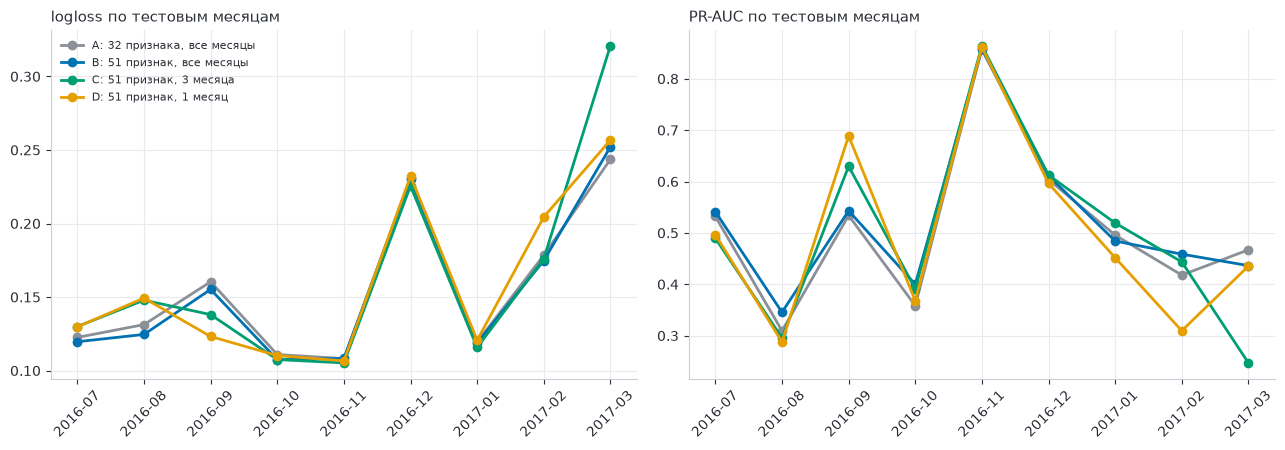

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
colors = {"A": GRAY, "B": BLUE, "C": GREEN, "D": ORANGE}
for metric, ax, title in [("logloss", axes[0], "logloss по тестовым месяцам"), ("pr_auc", axes[1], "PR-AUC по тестовым месяцам")]:
    for name in CONFIGS:
        g = res[res.config == name]
        ax.plot(g.month, g[metric], color=colors[name[0]], marker="o", lw=2, label=name)
    ax.set_title(title, loc="left", fontsize=11)
    ax.tick_params(axis="x", labelrotation=45)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout()
fig_rolling = fig
plt.show()

## 5. Калибровка и сдвиг доли оттока
Для модели B: средняя предсказанная вероятность и фактическая доля оттока по месяцам, а также logloss без поправки, с поправкой к доле последнего известного месяца (T−2) и со справочной поправкой к доле месяца T.

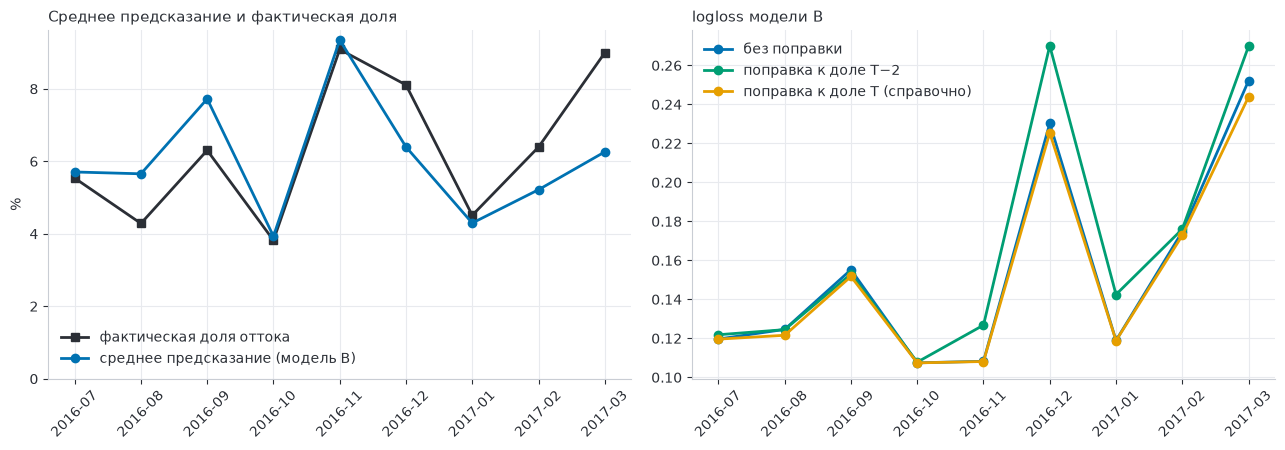

variant,без поправки,поправка к доле T (справочно),поправка к доле T−2
month,,,
2016-07,0.1196,0.1196,0.1218
2016-08,0.1246,0.1216,0.1245
2016-09,0.1552,0.1517,0.1530
2016-10,0.1074,0.1074,0.1078
2016-11,0.1082,0.1081,0.1268
2016-12,0.2302,0.2254,0.2700
2017-01,0.1189,0.1188,0.1425
2017-02,0.1747,0.1727,0.1760
2017-03,0.2521,0.2439,0.2698


In [9]:
calib = pd.DataFrame(calib_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
b = calib[calib.variant == "без поправки"]
axes[0].plot(b.month, 100 * b.actual_rate, color=INK, marker="s", lw=2, label="фактическая доля оттока")
axes[0].plot(b.month, 100 * b.mean_pred, color=BLUE, marker="o", lw=2, label="среднее предсказание (модель B)")
axes[0].set_ylabel("%")
axes[0].set_ylim(0, None)
axes[0].tick_params(axis="x", labelrotation=45)
axes[0].legend(frameon=False)
axes[0].set_title("Среднее предсказание и фактическая доля", loc="left", fontsize=11)
for variant, color in [("без поправки", BLUE), ("поправка к доле T−2", GREEN), ("поправка к доле T (справочно)", ORANGE)]:
    g = calib[calib.variant == variant]
    axes[1].plot(g.month, g.logloss, color=color, marker="o", lw=2, label=variant)
axes[1].set_title("logloss модели B", loc="left", fontsize=11)
axes[1].tick_params(axis="x", labelrotation=45)
axes[1].legend(frameon=False)
plt.tight_layout()
fig_calib = fig
plt.show()
calib.pivot(index="month", columns="variant", values="logloss").round(4)

## 6. Диагностика сдвига между месяцами
Классификатор (LightGBM, 100 деревьев) учится отличать клиентов месяца T−2 от клиентов месяца T по признакам (по 30 тысяч клиентов, отложенные 30% для оценки). AUC около 0,5 означает,
что месяцы по признакам почти неразличимы, чем выше AUC, тем сильнее сдвиг распределения признаков. Показаны также признаки, которые сдвигаются сильнее всего (по gain).

In [10]:
adv_rows = []
for month in TEST_MONTHS:
    m0 = ALL_MONTHS[ALL_MONTHS.index(month) - 2]
    a = load_month(m0, label_source(m0), 8).head(30000)
    b = load_month(month, label_source(month), 8).head(30000)
    both = pd.concat([a, b])
    prep = fit_prep(both)
    X = apply_prep(both, prep)[F2]
    z = np.r_[np.zeros(len(a)), np.ones(len(b))]
    i_tr, i_te = train_test_split(np.arange(len(both)), test_size=0.3, stratify=z, random_state=SEED)
    clf = lgb.LGBMClassifier(n_estimators=100, learning_rate=0.1, num_leaves=31, random_state=SEED, n_jobs=6, verbose=-1).fit(X.iloc[i_tr], z[i_tr])
    auc = roc_auc_score(z[i_te], clf.predict_proba(X.iloc[i_te])[:, 1])
    imp = pd.Series(clf.booster_.feature_importance(importance_type="gain"), index=F2).sort_values(ascending=False)
    adv_rows.append({"месяц": month[:7], "сравнение с": m0[:7], "AUC": round(auc, 3), "главные признаки": ", ".join(imp.index[:3])})
adv = pd.DataFrame(adv_rows)
adv

,месяц,сравнение с,AUC,главные признаки
0,2016-07,2016-05,0.924,"tenure_days, n_paid_tx, n_plans"
1,2016-08,2016-06,0.927,"tenure_days, days_to_expire, n_paid_tx"
2,2016-09,2016-07,0.994,"tenure_days, days_to_expire, ex_minus_td_minus..."
3,2016-10,2016-08,0.995,"days_between_last_two_tx, days_since_last_tx, ..."
4,2016-11,2016-09,0.991,"days_between_last_two_tx, ex_minus_td_minus_pl..."
5,2016-12,2016-10,0.896,"tenure_days, n_paid_tx, total_paid"
6,2017-01,2016-11,0.904,"tenure_days, days_to_expire, days_since_last_tx"
7,2017-02,2016-12,0.997,"tenure_days, ex_minus_td_minus_plan, days_betw..."
8,2017-03,2017-01,0.996,"ex_minus_td_minus_plan, days_between_last_two_..."


## 7. Итог для марта 2017 и сопоставление с `07_churn_model.ipynb`
Результаты конфигураций на официальных метках марта 2017 при зазоре в один месяц (обучение до января 2017) в сопоставлении с результатами `07_churn_model.ipynb`
(обучение на феврале 2017 без зазора и без новых признаков).

In [11]:
stage3 = pd.Series({"logloss": 0.2059, "pr_auc": 0.5891, "roc_auc": 0.8608}, name="07_churn_model (обучение на феврале, без зазора, 32 признака)")
cmp = pd.concat([march[["logloss", "pr_auc", "roc_auc"]].T, stage3], axis=1).T.round(4)
cmp

,logloss,pr_auc,roc_auc
"A: 32 признака, все месяцы",0.2436,0.4670,0.8275
"B: 52 признака, все месяцы",0.2521,0.4363,0.8133
"C: 52 признака, 3 месяца",0.3208,0.2470,0.7714
"D: 52 признака, 1 месяц",0.2567,0.4353,0.8015
"07_churn_model (обучение на феврале, без зазора, 32 признака)",0.2059,0.5891,0.8608


## 8. Запись в MLflow
Родительский запуск `rolling_validation_v2` с вложенными запусками по конфигурациям: параметры, метрики по месяцам (шаги), средние и мартовские значения; графики записываются в родительский запуск.

In [12]:
mlflow.set_tracking_uri("http://mlflow:5000")
EXPERIMENT = "churn_model"
if mlflow.get_experiment_by_name(EXPERIMENT) is None:
    mlflow.create_experiment(EXPERIMENT, artifact_location="mlflow-artifacts:/churn_model")
mlflow.set_experiment(EXPERIMENT)

with mlflow.start_run(run_name="rolling_validation_v2") as parent:
    mlflow.log_params({"train_share_pct": TRAIN_SHARE, "n_trees": N_TREES, "test_months": f"{TEST_MONTHS[0][:7]}..{TEST_MONTHS[-1][:7]}", "gap_months": 1})
    mlflow.set_tag("stage", "rolling_validation")
    mlflow.log_figure(fig_rates, "churn_rate_by_month.png")
    mlflow.log_figure(fig_rolling, "rolling_metrics.png")
    mlflow.log_figure(fig_calib, "calibration_by_month.png")
    adv.to_csv("/tmp/adversarial_auc.csv", index=False)
    mlflow.log_artifact("/tmp/adversarial_auc.csv")
    for name, (feats, k) in CONFIGS.items():
        g = res[res.config == name].reset_index(drop=True)
        with mlflow.start_run(run_name=name, nested=True):
            mlflow.log_params({"n_features": len(feats), "window_months": "all" if k is None else k, "n_trees": N_TREES})
            for step, r in g.iterrows():
                mlflow.log_metrics({"logloss": r.logloss, "pr_auc": r.pr_auc, "roc_auc": r.roc_auc, "mean_pred": r.mean_pred, "actual_rate": r.actual_rate}, step=step)
            mlflow.log_metrics({
                "mean_logloss": g.logloss.mean(), "mean_pr_auc": g.pr_auc.mean(), "mean_roc_auc": g.roc_auc.mean(),
                "march_logloss": g.logloss.iloc[-1], "march_pr_auc": g.pr_auc.iloc[-1], "march_roc_auc": g.roc_auc.iloc[-1],
            })
print("записано в MLflow, интерфейс: http://localhost:5001")

2026/10/28 11:24:28 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/28 11:24:28 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git branch is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



2026/10/28 11:24:28 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git repository URL is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet



🏃 View run A: 32 признака, все месяцы at: http://mlflow:5000/#/experiments/1/runs/6d8b1986146645bd82e03a16b764caf2
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run B: 52 признака, все месяцы at: http://mlflow:5000/#/experiments/1/runs/6a4957481aff42dc8fcc87f97a3a1448
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run C: 52 признака, 3 месяца at: http://mlflow:5000/#/experiments/1/runs/86585dcbb8b644e79d22a58549f3f076
🧪 View experiment at: http://mlflow:5000/#/experiments/1


🏃 View run D: 52 признака, 1 месяц at: http://mlflow:5000/#/experiments/1/runs/6296bfd5167a4d7889e2a86a45fe6f69
🧪 View experiment at: http://mlflow:5000/#/experiments/1
🏃 View run rolling_validation_v2 at: http://mlflow:5000/#/experiments/1/runs/9361ebfdf2d442fe91cfb63c7e11adfe
🧪 View experiment at: http://mlflow:5000/#/experiments/1


записано в MLflow, интерфейс: http://localhost:5001


## Выводы
- **Качество сильно зависит от месяца.** У модели B logloss колеблется от 0,107 (октябрь 2016) до 0,252 (март 2017), PR-AUC от 0,35 (август 2016) до 0,86 (ноябрь 2016); доля оттока по собственной разметке меняется от 3,8% до 18,0%. Сдвиг между февралём и мартом 2017 не уникален. Среднее предсказание близко к фактической доле в июле и октябре–ноябре 2016 и в январе 2017, завышает её в августе и сентябре 2016, занижает в декабре 2016, феврале и марте 2017 (в марте 6,3% против 9,0%).
- **Расширенные признаки дают небольшой средний выигрыш.** Среднее по девяти тестовым месяцам: конфигурация A (32 признака) logloss 0,1562, PR-AUC 0,5084, ROC-AUC 0,8806; конфигурация B (52 признака) 0,1546, 0,5198, 0,8804. В июле–октябре 2016 и феврале 2017 B лучше A, в марте 2017 хуже (0,2521 против 0,2436). Для каждой конфигурации выполнено одно обучение, интервалы не оценивались, различие сопоставимо с изменчивостью между месяцами.
- **Длинная история обучения лучше короткой.** Все допустимые месяцы (B): logloss 0,1546; три последних месяца (C): 0,1630; один последний (D): 0,1592. В марте C даёт 0,3208 и PR-AUC 0,247, то есть короткое окно делает модель нестабильной.
- **Поправка логитов не решает проблему.** Сдвиг к доле оттока последнего известного месяца (T−2) ухудшает logloss в большинстве месяцев (декабрь 2016: с 0,2302 до 0,2700; январь 2017: с 0,1189 до 0,1425; март 2017: с 0,2521 до 0,2698), потому что доли оттока месяцев T−2 и T различаются. Справочный сдвиг к фактической доле месяца T улучшает logloss не более чем на 0,008. Основная часть потерь связана с ранжированием клиентов, а не с общим уровнем вероятностей.
- **Месяцы по признакам различимы почти полностью.** Классификатор «месяц T−2 или месяц T» даёт AUC от 0,90 до 0,997. Часть сдвига возникает по построению: стаж и накопленные счётчики истории растут вместе с календарём, потому что данные начинаются в январе 2015 года. Признаки по скользящим окнам, которые должны быть устойчивее, проверены в `11_stable_features.ipynb`: заметного выигрыша они не дали.
- **Ограничения.** Модели обучены один раз с фиксированным числом деревьев (416), подобранным на декабре 2016 (самом трудном месяце); обучающие месяцы взяты с долей клиентов 20%. До января 2017 включительно метки собственные, тест февраля и марта 2017 на официальных метках. Результат марта при зазоре хуже, чем в `07_churn_model.ipynb` (logloss 0,2436 и 0,2521 против 0,2059): различие связано в основном с составом клиентов в обучающих месяцах (подробнее в `11_stable_features.ipynb`, раздел 6).